# 04 · Exams and repetitions

This notebook decides, once and for all, which patients are used to evaluate the models and which ones are used to train them. Every strategy reads the same two files. That is why the comparison between strategies is paired: in repetition 37, all strategies train with the same patients and are evaluated on the same exam.

Two terms are used in the whole project:
- An **exam** is a group of 40 patients of the target cohort (CPTAC or SMC 2018) that is never used for training. There are 5 exams per cohort.
- A **repetition** is a random choice of n local patients among the patients that are not in the exam. There are 100 repetitions per exam and per n (n = 10, 15, 20, 40, and 80 only in SMC).

Both are **stratified by TP53**: each group keeps the proportion of mutated tumors of its cohort. This way a group of 10 patients never ends up without mutated tumors.

**Input:** `data/processed/y_cptac.csv` and `data/processed/y_smc_2018.csv`. Only the labels are needed. The expression is not used here.

**Output:**
- `data/experiment/examenes.csv` (exams) and `data/experiment/repeticiones.csv` (repetitions). Column names are in Spanish: `cohorte` = cohort, `examen` = exam, `repeticion` = repetition, `muestra` = sample ID.
- `results/tables/04_resumen_examenes.csv` and two figures in `results/figures/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "processed"
OUT = ROOT / "data" / "experiment"
FIG = ROOT / "results" / "figures"
TAB = ROOT / "results" / "tables"
for folder in (OUT, FIG, TAB):
    folder.mkdir(parents=True, exist_ok=True)

FILES = {"CPTAC": "cptac", "SMC 2018": "smc_2018"}
N_LOCAL = {"CPTAC": [10, 15, 20, 40], "SMC 2018": [10, 15, 20, 40, 80]}
N_EXAM, N_EXAMS, N_REPS = 40, 5, 100
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## Step 1 · Load the labels

`y = 1` means TP53 mutated. The index is the sample ID, the same one used by the rows of `X_*.parquet`.

In [2]:
labels = {name: pd.read_csv(DATA / f"y_{file}.csv", index_col=0).y for name, file in FILES.items()}
pd.DataFrame({name: {"patients": len(y), "mutated": int(y.sum()), "% mutated": round(100 * y.mean(), 1)}
              for name, y in labels.items()}).T

,patients,mutated,% mutated
CPTAC,105.0,41.0,39.0
SMC 2018,167.0,81.0,48.5


## Step 2 · Choose the exams and the repetitions

The random seeds are fixed. Anyone who runs this notebook gets exactly the same groups:
- Exam `e` (0 to 4): seed `2026 + e`.
- Repetition `r` of size `n` in exam `e`: seed `100000·e + 1000·n + r`.

In [3]:
exam_rows, rep_rows = [], []
for name, y in labels.items():
    ids, labels_ = y.index.to_numpy(), y.to_numpy()
    for e in range(N_EXAMS):
        rest, exam = train_test_split(np.arange(len(y)), test_size=N_EXAM, stratify=labels_, random_state=2026 + e)
        exam_rows += [{"cohorte": name, "examen": e + 1, "muestra": m} for m in ids[exam]]
        for n in N_LOCAL[name]:
            for r in range(N_REPS):
                local, _ = train_test_split(rest, train_size=n, stratify=labels_[rest],
                                            random_state=100000 * e + 1000 * n + r)
                rep_rows += [{"cohorte": name, "examen": e + 1, "n": n, "repeticion": r, "muestra": m}
                             for m in ids[local]]

exams, reps = pd.DataFrame(exam_rows), pd.DataFrame(rep_rows)
print(f"examenes.csv: {len(exams):,} rows · repeticiones.csv: {len(reps):,} rows")

examenes.csv: 400 rows · repeticiones.csv: 125,000 rows


## Step 3 · Check that everything is right

If any check fails, the notebook stops here. The checks are the following:
1. Every exam has 40 patients.
2. No local patient of a repetition is in its exam.
3. Every repetition has exactly n patients, with at least 1 mutated and 1 not mutated tumor.

In [4]:
for (name, e), exam in exams.groupby(["cohorte", "examen"]):
    assert len(exam) == N_EXAM, (name, e)
    local = reps[(reps.cohorte == name) & (reps.examen == e)]
    assert not local.muestra.isin(exam.muestra).any(), f"{name} exam {e}: a local patient is in the exam"

y_all = pd.concat(labels.values())
check = reps.assign(y=reps.muestra.map(y_all)).groupby(["cohorte", "examen", "n", "repeticion"]).y.agg(["size", "sum"])
assert (check["size"] == check.index.get_level_values("n")).all(), "a repetition does not have n patients"
assert ((check["sum"] > 0) & (check["sum"] < check["size"])).all(), "a repetition has only one class"
print("All good:", len(check), "repetitions checked")

All good: 4500 repetitions checked


In [5]:
summary = (exams.assign(y=exams.muestra.map(y_all))
           .groupby(["cohorte", "examen"]).y.agg(patients_in_exam="size", mutated_in_exam="sum"))
summary["outside_the_exam"] = [len(labels[name]) - N_EXAM for name, _ in summary.index]
summary.to_csv(TAB / "04_resumen_examenes.csv")
summary

patients_in_exam  mutated_in_exam  outside_the_exam
cohorte  examen                                                     
CPTAC    1                     40               16                65
         2                     40               16                65
         3                     40               16                65
         4                     40               16                65
         5                     40               16                65
SMC 2018 1                     40               19               127
         2                     40               19               127
         3                     40               19               127
         4                     40               19               127
         5                     40               19               127

**How to read it:** every exam has 40 patients and almost the same number of mutated tumors (because of the stratification). `outside_the_exam` are the patients from which the local patients are drawn. They are also used to normalize the cohort, without their labels.

## Step 4 · Figures

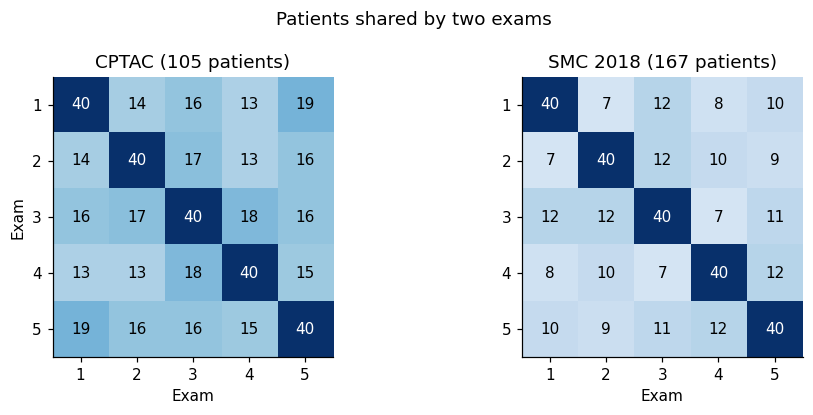

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, name in zip(axes, FILES):
    sets = [set(g.muestra) for _, g in exams[exams.cohorte == name].groupby("examen")]
    shared = np.array([[len(a & b) for b in sets] for a in sets])
    ax.imshow(shared, cmap="Blues", vmin=0, vmax=N_EXAM)
    for i in range(N_EXAMS):
        for j in range(N_EXAMS):
            ax.text(j, i, shared[i, j], ha="center", va="center", color="white" if shared[i, j] > 25 else "black")
    ax.set_xticks(range(N_EXAMS), range(1, N_EXAMS + 1))
    ax.set_yticks(range(N_EXAMS), range(1, N_EXAMS + 1))
    ax.set_title(f"{name} ({len(labels[name])} patients)")
    ax.set_xlabel("Exam")
axes[0].set_ylabel("Exam")
fig.suptitle("Patients shared by two exams")
plt.tight_layout()
fig.savefig(FIG / "04_solapamiento_examenes.png", bbox_inches="tight")

**Figure 04-1 · How to read it:** the diagonal is 40 (each exam with itself). Outside the diagonal, how many patients two exams share. Exams share patients because the cohorts are small. That is why the 5 exams are not treated as different cohorts: the conclusion is valid for each cohort, and CPTAC and SMC are analyzed separately.

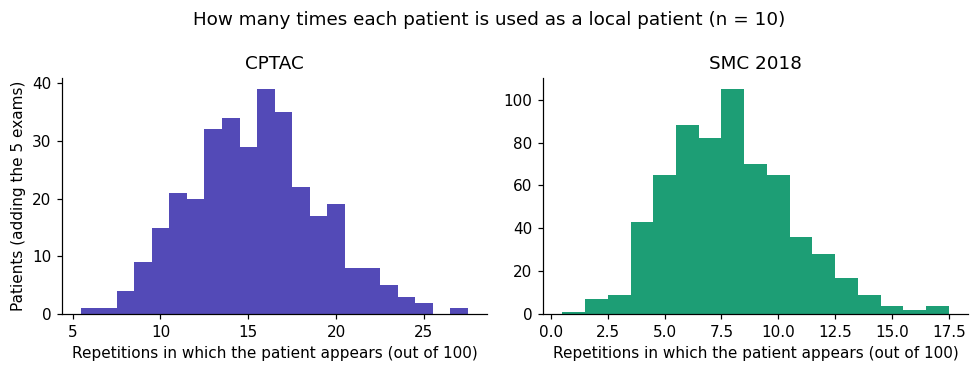

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, name in zip(axes, FILES):
    uses = reps[(reps.cohorte == name) & (reps.n == 10)].groupby(["examen", "muestra"]).size()
    ax.hist(uses, bins=np.arange(uses.min(), uses.max() + 2) - 0.5, color="#534AB7" if name == "CPTAC" else "#1D9E75")
    ax.set_title(name)
    ax.set_xlabel("Repetitions in which the patient appears (out of 100)")
axes[0].set_ylabel("Patients (adding the 5 exams)")
fig.suptitle("How many times each patient is used as a local patient (n = 10)")
plt.tight_layout()
fig.savefig(FIG / "04_uso_pacientes.png", bbox_inches="tight")

**Figure 04-2 · How to read it:** with n = 10, each patient outside the exam should appear in about 100 × 10 / (patients outside the exam) repetitions. That is ~15 in CPTAC (65 outside) and ~8 in SMC (127 outside). If one patient appeared in almost every repetition, that patient would weigh too much in the results.

## Step 5 · Save

In [8]:
exams.to_csv(OUT / "examenes.csv", index=False)
reps.to_csv(OUT / "repeticiones.csv", index=False)
print("Saved in", OUT.relative_to(ROOT))

Saved in data/experiment


From here on, no notebook chooses patients at random again. All of them read `examenes.csv` and `repeticiones.csv`.